# Week 6 Homework: Your Answers vs. Your Vibe-Coded Dashboard

**Week 4 dashboard link:** _(paste your Streamlit URL)_ https://movielens-dashboard-wcw7dpkqydfn3xon5zhj7z.streamlit.app/

---

Two weeks ago you vibe-coded a MovieLens dashboard before you had the tools to judge it. Since then you've had the stats lecture (Week 5) and this week's EDA lecture. Now you do it the real way: answer the same 4 questions yourself, by hand, then audit the dashboard against your own work.

**Ground rules**

- 🚫 **No AI for code or answers in Parts 1 and 2.** Lecture notebooks, pandas/seaborn docs, Google, and Stack Overflow are all fair game. Write Part 3 in your own words too.
- 🔒 **Lock in before you peek.** Finish Parts 1 and 2 (answers written down) *before* you open your dashboard. If you look first, you'll anchor on its numbers and the comparison is worthless.
- 🔢 **Show your numbers.** Every answer needs actual values (counts, averages, titles), not just a vibe.
- ✏️ Written answers go in markdown cells (double-click to edit, Shift+Enter to render). Most are 2 to 4 sentences. Short and specific beats long and vague.

## The data

`movie_ratings.csv` has one row per rating: 100,000 ratings from 943 users on 1,682 movies.

- `user_id`, `movie_id`: who rated, which movie
- `rating`: 1 to 5 stars
- `timestamp`, `rating_year`: when the rating was given
- `age`, `gender`, `occupation`, `zip_code`: the rater
- `title`: movie title, with release year in parentheses
- `year`, `decade`: the movie's release year and decade
- `genres`: all of the movie's genres in one string, separated by the pipe character (a movie can have several)

## Setup

In [ ]:
/workspaces/ds-fall-2026/.venv/bin/python -m pip install -U pandas matplotlib seaborn ipykernel

In [1]:
import sys
print(sys.executable)

/workspaces/ds-fall-2026/.venv/bin/python


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Works whether this notebook sits in the week folder or inside exercise/
data_path = next(p for p in ["data/movie_ratings.csv", "../data/movie_ratings.csv"] if Path(p).exists())
df = pd.read_csv(data_path)
df.head()

,user_id,movie_id,rating,timestamp,age,gender,occupation,zip_code,title,year,decade,genres,rating_year
0,196,242,3,1997-12-04 15:55:49,49,M,writer,55105,Kolya (1996),1996.0,1990.0,Comedy,1997
1,186,302,3,1998-04-04 19:22:22,39,F,executive,00000,L.A. Confidential (1997),1997.0,1990.0,Crime|Film-Noir|Mystery|Thriller,1998
2,22,377,1,1997-11-07 07:18:36,25,M,writer,40206,Heavyweights (1994),1994.0,1990.0,Children|Comedy,1997
3,244,51,2,1997-11-27 05:02:03,28,M,technician,80525,Legends of the Fall (1994),1994.0,1990.0,Drama|Romance|War|Western,1997
4,166,346,1,1998-02-02 05:33:16,47,M,educator,55113,Jackie Brown (1997),1997.0,1990.0,Crime|Drama,1998


---
# Part 1: Methodology

## 1.1 Know your data first

Before answering anything, check what you're working with: shape, column types, missing values, duplicate rows, and the range of the numeric columns.

In [3]:
# Your data checks here
print("Shape:", df.shape)

print("\nColumn types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nNumeric ranges:")
print(df.select_dtypes(include="number").agg(["min", "max"]).T)

print("\nMovies with missing year/decade:")
display(
    df[df["year"].isnull()][
        ["movie_id", "title", "year", "decade"]
    ].drop_duplicates()
)

Shape: (100000, 13)

Column types:
user_id          int64
movie_id         int64
rating           int64
timestamp          str
age              int64
gender             str
occupation         str
zip_code           str
title              str
year           float64
decade         float64
genres             str
rating_year      int64
dtype: object

Missing values:
user_id         0
movie_id        0
rating          0
timestamp       0
age             0
gender          0
occupation      0
zip_code        0
title           0
year           30
decade         30
genres          0
rating_year     0
dtype: int64

Duplicate rows:
0

Numeric ranges:
                min     max
user_id         1.0   943.0
movie_id        1.0  1682.0
rating          1.0     5.0
age             7.0    73.0
year         1922.0  1998.0
decade       1920.0  1990.0
rating_year  1997.0  1998.0

Movies with missing year/decade:


,movie_id,title,year,decade
2172,267,unknown,NaN,NaN
6459,1128,Heidi Fleiss: Hollywood Madam (1995),NaN,NaN
23637,1412,Land Before Time III: The Time of the Great Gi...,NaN,NaN
69734,1635,Two Friends (1986),NaN,NaN
78008,1201,Marlene Dietrich: Shadow and Light (1996),NaN,NaN


**✏️ Data notes:** _(What did you find? Anything missing, duplicated, or surprising? What did you do about it, and why?)_

## 1.2 Decide before you chart

In Week 4 the questions were ambiguous on purpose. This is where *you* commit to an interpretation. Fill it in now, and update it if you change your mind while working (just say so).

**Q1 Genre breakdown**
- What you have to decide: What am I counting, whether it is ratings or movies, way to handle movies that have multiiple genres.
- My choice: I will count unique movies in each genre. If a movie has several genres, I will count it once in each genre it belongs to.
- Why: It is because I want the breakdown to show how many movies are available in each genre, rather than how many times those movies were rated.

**Q2 Genre satisfaction**
- What you have to decide: "Average rating" of what? How do I treat genres that have very little data?
- My choice: I will use the average of all user ratings for each genre and only compare genres that have at least 100 ratings.
- Why: This gives a simple measure of how satisfied users were with each genre, while avoiding conclusions based on very small samples.

**Q3 Ratings over time**
- What you have to decide: Is every year backed by the same amount of data? What do I do with movies that have no release year?
- My choice: I will calculate the average rating by movie release year and also check how many ratings each year has. I will leave out movies with missing release years for this question.
- Why: Some years have much more data than others, so I should not treat every yearly average as equally reliable. Movies without a release year cannot be placed correctly on the timeline.

**Q4 Best movies**
- What you have to decide: What is a movie's rating (the mean of what)? Is "at least 50" ≥ or >? What if there's a tie?
- My choice: A movie's rating will be the mean of all user ratings for that movie. "At least 50" means 50 or more ratings (≥ 50). If there is a tie, I will rank the movie with more ratings higher.
- Why: Requiring at least 50 ratings makes the ranking more reliable, and using the number of ratings as a tie-breaker gives more weight to the result supported by more viewers.

---
# Part 2: Results (by hand, no AI)

Answer each question with a chart or table **and** a written answer with real numbers. Pick the chart type yourself and be ready to defend it in Part 3. Add as many code cells as you need.

## Q1. Genre breakdown

**What's the distribution of genres among the movies that were rated?**

<details>
<summary>Stuck on movies with several genres? Hint</summary>

`genres` is one string like `Crime|Film-Noir|Mystery|Thriller`. To get one row per genre:

```python
genre_df = df.assign(genre=df['genres'].str.split('|')).explode('genre')
```

Heads up: after this, a movie with 3 genres takes up 3 rows. Think about what that does to anything you count or average. Exploding is fine for "how often does a genre show up", but be careful calling the result "market share" (the percentages add up to more than 100%).
</details>

,movie_count,percent_of_movies
genre,,
Drama,725,43.1
Comedy,505,30.0
Thriller,251,14.9
Action,251,14.9
Romance,247,14.7
Adventure,135,8.0
Children,122,7.3
Crime,109,6.5
Sci-Fi,101,6.0


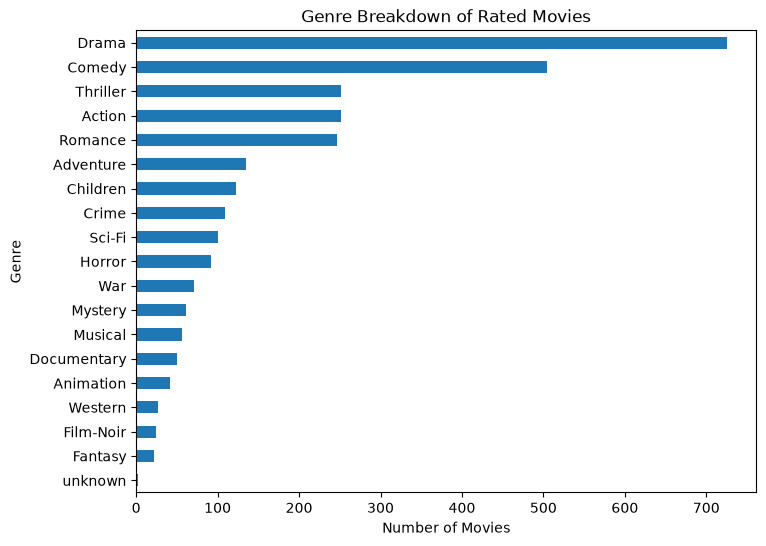

In [6]:
# Q1: your code here

# One row per unique movie
movies = df[['movie_id', 'genres']].drop_duplicates()

# To split movies with multiple genres into separate rows
genre_df = movies.assign(
    genre=movies['genres'].str.split('|')
).explode('genre')

# Count unique movies in each genre
genre_counts = genre_df['genre'].value_counts()

genre_summary = pd.DataFrame({
    'movie_count': genre_counts,
    'percent_of_movies': (genre_counts / movies['movie_id'].nunique() * 100).round(1)
})

display(genre_summary)




genre_counts.sort_values().plot(
    kind='barh',
    figsize=(8, 6),
    xlabel='Number of Movies',
    ylabel='Genre',
    title='Genre Breakdown of Rated Movies'
)

plt.show()

**✏️ My answer (with numbers):** _(Which genres dominate, by how much, and what exactly did you count?)_

**✏️ My answer (with numbers):** I counted the 1682 unique movies, not the 100,000 individual ratings (meaning the actual dataset has 100k rating rows, but those ratings are about only 1682 different movies, so I counted each only once). Drama was the most common genre with 725 movies (43.1%), followed by Comedy with 505 (30.0%); Action and Thriller each had 251 (14.9%), and Romance had 247 (14.7%). Drama had 220 more movies than Comedy, so it is visibly clear that it is the dominant genre. Movies with multiple genres were counted once in each genre they belong to, so these percentages overlap and are not supposed to add up to 100%.

## Q2. Genre satisfaction

**Which genres have the highest average rating? Which have the lowest?**

Show how much data is behind each average (for example, the count next to it). An average of 10 ratings and an average of 10,000 ratings are not the same kind of evidence.

,avg_rating,rating_count
genre,,
Film-Noir,3.92,1733
War,3.82,9398
Drama,3.69,39895
Documentary,3.67,758
Mystery,3.64,5245
Crime,3.63,8055
Romance,3.62,19461
Western,3.61,1854
Animation,3.58,3605


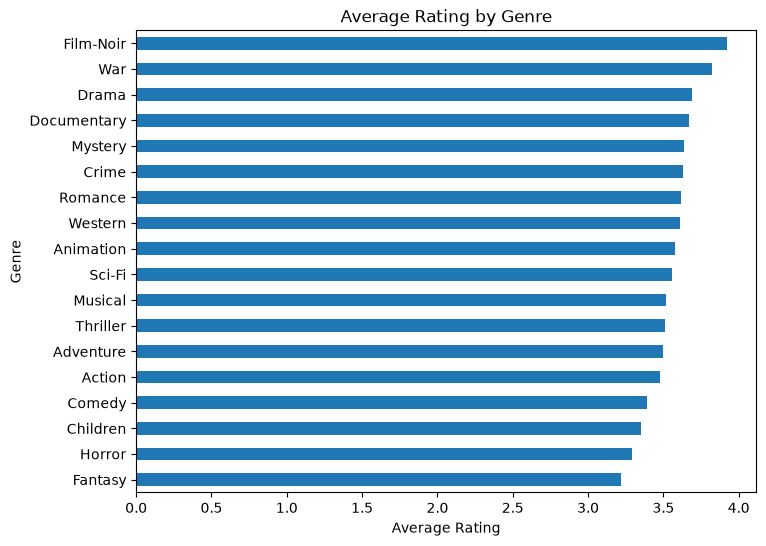

In [7]:
# Q2: your code here
# Split the genres so each rating can count toward every genre the movie belongs to
genre_ratings = df.assign(
    genre=df['genres'].str.split('|')
).explode('genre')

# Average rating and number of ratings for each genre
genre_stats = (
    genre_ratings
    .groupby('genre')['rating']
    .agg(['mean', 'count'])
    .rename(columns={'mean': 'avg_rating', 'count': 'rating_count'})
)

# Keep only genres with at least 100 ratings
genre_stats = genre_stats[
    genre_stats['rating_count'] >= 100
].sort_values('avg_rating', ascending=False)

genre_stats['avg_rating'] = genre_stats['avg_rating'].round(2)

display(genre_stats)

# Plot average rating by genre
genre_stats['avg_rating'].sort_values().plot(
    kind='barh',
    figsize=(8, 6),
    xlabel='Average Rating',
    ylabel='Genre',
    title='Average Rating by Genre'
)

plt.show()

**✏️ My answer (with numbers):** _(Top and bottom genres, their averages, and how much data each one rests on.)_

**✏️ My answer (with numbers):** After keeping only genres with at least 100 ratings, Film-Noir had the highest average rating at 3.92 from 1733 ratings, followed by War at 3.82 from 9398 ratings. On the other end, Fantasy had the lowest average at 3.22 from 1352 ratings, followed by Horror at 3.29 from 5317 ratings and Children at 3.35 from 7182 ratings. One thing I noticed is that some genres have much more data behind them, like Drama with 39,895 ratings and an average of 3.69, so I would have more confidence in that average than one based on a much smaller number of ratings.

## Q3. Ratings over time

**How has the mean rating changed across movie release years?**

Show how many ratings each year is based on, alongside the trend.

,year,mean_rating,rating_count
0,1922,3.56,54
1,1926,3.00,2
2,1930,3.78,18
3,1931,4.00,44
4,1932,3.83,12
...,...,...,...
66,1994,3.42,9034
67,1995,3.41,12389
68,1996,3.31,18744
69,1997,3.31,15384


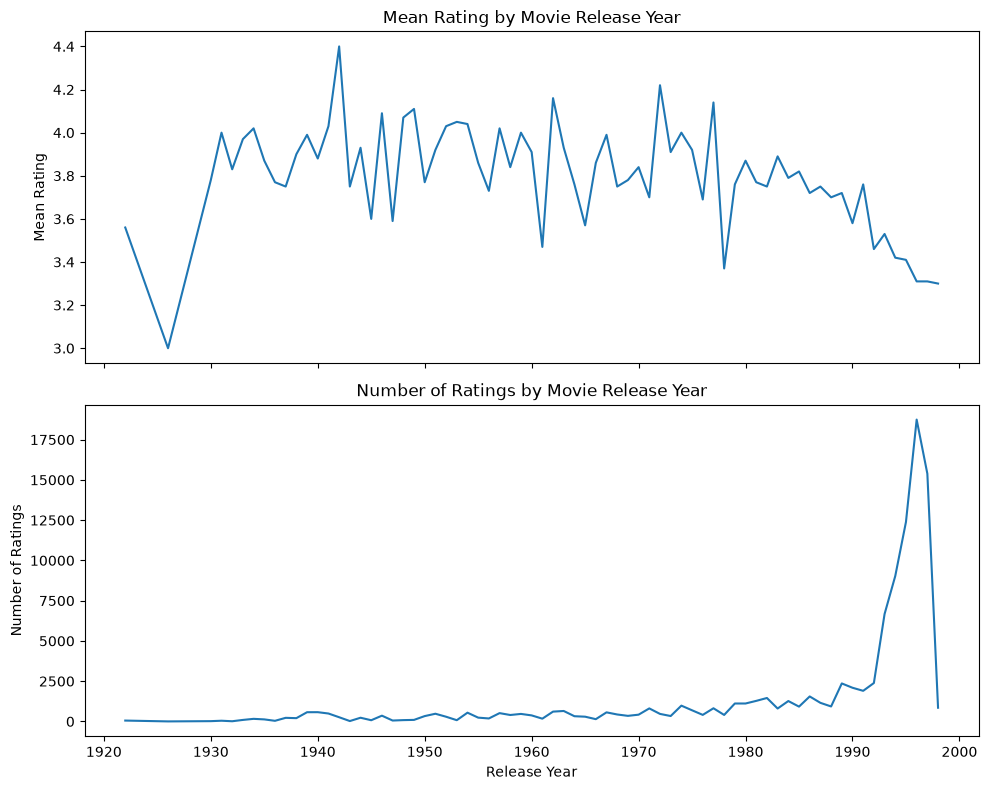

In [9]:
# Q3: your code here




year_data = df.dropna(subset=['year'])

# Mean rating and number of ratings for each release year
year_stats = (
    year_data
    .groupby('year')['rating']
    .agg(['mean', 'count'])
    .reset_index()
    .rename(columns={'mean': 'mean_rating', 'count': 'rating_count'})
)

year_stats['year'] = year_stats['year'].astype(int)
year_stats['mean_rating'] = year_stats['mean_rating'].round(2)



display(year_stats)



# Show the rating trend and how much data is behind each year
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

axes[0].plot(
    year_stats['year'],
    year_stats['mean_rating']
)
axes[0].set_title('Mean Rating by Movie Release Year')
axes[0].set_ylabel('Mean Rating')

axes[1].plot(
    year_stats['year'],
    year_stats['rating_count']
)
axes[1].set_title('Number of Ratings by Movie Release Year')
axes[1].set_xlabel('Release Year')
axes[1].set_ylabel('Number of Ratings')

plt.tight_layout()
plt.show()

**✏️ My answer (with numbers):** _(What's the trend? Is it equally believable across the whole timeline?)_

**✏️ My answer (with numbers):** The mean ratings generally seem higher for older movies and trend downward for newer release years, although the early years move around a lot because some of them have very little data. For example, movies released in 1942 have an average rating of about 4.40 based on 261 ratings, while 1996 and 1997 are both around 3.31 based on 18,744 and 15384 ratings. Movies from 1998 average about 3.30 from 851 ratings. I would be careful with years like 1926, though, because its average of 3.00 is based on only 2 ratings, so that number is not nearly as reliable.

## Q4. Best movies, with a floor

**What are the 5 best-rated movies that have at least 50 ratings? What changes if you raise the floor to 150?**

In [10]:
# Q4: your code here
# Average rating and number of ratings for each movie
movie_stats = (
    df.groupby(['movie_id', 'title'])['rating']
    .agg(['mean', 'count'])
    .reset_index()
    .rename(columns={
        'mean': 'avg_rating',
        'count': 'rating_count'
    })
)

# At least 50 ratings
top_50 = (
    movie_stats[movie_stats['rating_count'] >= 50]
    .sort_values(
        ['avg_rating', 'rating_count'],
        ascending=[False, False]
    )
    .head(5)
)

# At least 150 ratings
top_150 = (
    movie_stats[movie_stats['rating_count'] >= 150]
    .sort_values(
        ['avg_rating', 'rating_count'],
        ascending=[False, False]
    )
    .head(5)
)

top_50['avg_rating'] = top_50['avg_rating'].round(2)
top_150['avg_rating'] = top_150['avg_rating'].round(2)

print("Top 5 with at least 50 ratings:")
display(top_50[['title', 'avg_rating', 'rating_count']])

print("Top 5 with at least 150 ratings:")
display(top_150[['title', 'avg_rating', 'rating_count']])

Top 5 with at least 50 ratings:


,title,avg_rating,rating_count
407,"Close Shave, A (1995)",4.49,112
317,Schindler's List (1993),4.47,298
168,"Wrong Trousers, The (1993)",4.47,118
482,Casablanca (1942),4.46,243
113,Wallace & Gromit: The Best of Aardman Animatio...,4.45,67


Top 5 with at least 150 ratings:


,title,avg_rating,rating_count
317,Schindler's List (1993),4.47,298
482,Casablanca (1942),4.46,243
63,"Shawshank Redemption, The (1994)",4.45,283
602,Rear Window (1954),4.39,209
11,"Usual Suspects, The (1995)",4.39,267


**✏️ My answer (with numbers):** _(Both top-5 lists. Which movies dropped out or moved in when the floor went up, and what does that say about small samples?)_

**My answer (with numbers):** With a minimum of 50 ratings, *A Close Shave* ranked first with an average of 4.49 from 112 ratings, followed by *Schindler's List* at 4.47 from 298 ratings. When I raised the minimum to 150 ratings, *A Close Shave*, *The Wrong Trousers*, and *Wallace & Gromit: The Best of Aardman Animation* dropped out because they only had 112, 118, and 67 ratings. *Schindler's List* then moved to first, while *The Shawshank Redemption*, *Rear Window*, and *The Usual Suspects* moved into the top five. This shows that movies with smaller samples can look extremely highly rated, but raising the minimum gives a ranking backed by more viewers.

> 🔒 **Stop here.** Parts 1 and 2 should be completely filled in before you open your dashboard.

---
# Part 3: Analysis

Now open your Week 4 dashboard.

## 3.1 How the dashboard got built

Paste 2 prompts that shaped it (from your build log, or from your AI chat history if you didn't keep a log; don't invent any). For each one: what did you ask, what did the AI give you first, and what did you change or accept without checking?

**Prompt 1**
- What I asked: I asked ChatGPT (Astra, Model 6, Effort: Very High) to act like me, follow my styles just like I told it many times before in other conversations, and help me complete the MovieLens dashboard assignment based on the instructions I provided. I also told it to explain the task first in simple words and then guide me step by step because I wanted to do the GitHub and submission parts myself. I later uploaded the actual `movie_ratings.csv` file so it could use the correct course data.


- AI's first attempt: It built and tested a local version of the dashboard, created the 4 required movie analysis sections and working controls, and gave me a beginner-friendly step-by-step guide for testing and publishing it. It also created a build log for the project. It also popped up a permission asking message and asked for my github information so it can deploy itself. I denied and told to guide me step by step and I will do the streamlit deploy part by myself following the instructions


- What I changed (or accepted without checking): I checked that the dashboard showed the expected 1682 movies and 100k ratings, tested the controls, and looked through the 4 sections. I mostly accepted the calculations and structure at that point and focused on making sure the app worked before publishing. There was little issue with the darm-mode feature which I had to fix too.

**Prompt 2** After checking the first version, I asked it to make the dashboard look more polished and less "monotonous." I specifically changed the credit line to "Developed By The Supervision of Mubasshir Al Shahriar, Powered By: Codex," asked for a more natural design that matched my style, and told it to change the chart colors and review everything from the original assignment before I submitted.


- AI's first attempt: It redesigned the dashboard using an ivory, rust, indigo, and gold theme, improved the typography, chart labels, and movie rankings, and rechecked the 4 charts, calculations, and controls. It also finished the review notes and prepared the project for GitHub and Streamlit deployment.


- What I changed (or accepted without checking): Nothing. I checked, and accepted. Then asked to guide me step by step on how to deploy on streamlit.

## 3.2 Compare the answers

Read the answer off your dashboard for each question and put it next to yours.

**Q1**
- Dashboard says: Drama shows up the most with 725 movies, followed by Comedy with 505. Action and Thriller both have 251, and Romance has 247.
- I say: I got the same results. Drama was the most common with 725 movies (43.1%), followed by Comedy with 505 (30.0%), while Action and Thriller each had 251 and Romance had 247.
- Same? (yes / partly / no): Yes.
- If different, why? There was no difference. Both counted unique movies instead of individual rating rows, and a movie with multiple genres was counted once in each genre it belongs to.

**Q2**
- Dashboard says: Film-Noir has the highest average rating among the named genres at 3.92, followed by War at 3.82, while Fantasy has the lowest at 3.22. It also shows an `unknown` category at 3.20.
- I say: Film-Noir was also the highest at 3.92 from 1,733 ratings, followed by War at 3.82 from 9398 ratings. Fantasy was the lowest genre I kept at 3.22 from 1,352 ratings.
- Same? (yes / partly / no): Partly.
- If different, why? The main result is the same, but I decided beforehand to only compare genres with at least 100 ratings. The dashboard still displays `unknown`, which only has 10 ratings, although it treats it as an uncategorized label instead of calling it the lowest named genre.

**Q3**
- Dashboard says: Mean ratings are in general higher for older movies and trend lower for newer release years. Movies with missing release years are left out of this chart, and the dashboard lets me check how many ratings are behind each year.
- I say: I found the same overall trend. For example, 1942 averaged about 4.40 from 261 ratings, while 1996 and 1997 were both around 3.31 from 18744 and 15384 ratings, and 1998 averaged about 3.30 from 851 ratings.
- Same? (yes / partly / no): Yes.
- If different, why? There was no real difference in the calculation. Both use movie release year, average the individual ratings for each year, and leave out the 30 ratings where the movie has no release year.

**Q4**
- Dashboard says: With at least 50 ratings, the top five are *A Close Shave*, *Schindler's List*, *The Wrong Trousers*, *Casablanca*, and *Wallace & Gromit: The Best of Aardman Animation*. When the minimum goes up to 150, only *Schindler's List* and *Casablanca* stay, while *The Shawshank Redemption*, *Rear Window*, and *The Usual Suspects* move in.
- I say: I got the same two lists. *A Close Shave* was first at the 50-rating floor with a 4.49 average from 112 ratings, but at 150 it drops out and *Schindler's List* becomes first with a 4.47 average from 298 ratings.
- Same? (yes / partly / no): Yes.
- If different, why? There was no difference. Both calculate each movie's average from all of its ratings and treat "at least 50" and "at least 150" as greater than or equal to those numbers.

**When numbers differ, check these first.** Most mismatches come from one of these:

- Counting **ratings** vs. counting **movies**
- One row per rating vs. **one row per rating per genre** (after exploding)
- **Mean of all ratings** vs. the mean of each movie's average
- "At least 50" as ≥ vs. >, or applying the floor before vs. after another step
- What happened to movies with a **missing year**
- Genres with **tiny sample sizes** left in or filtered out

**✏️ Pick two questions and explain what's going on** (2 to 3 sentences each). Track down the *actual cause*: read your dashboard's code, or re-run it with one change. "The AI did it differently" is not an explanation. If the answers match, say why you now trust them.

**Q2:** This was the one place where my method was a little different. I filtered out genres with fewer than 100 ratings, while the dashboard still displays the `unknown` category even though it only has 10 ratings; however, the dashboard does not treat `unknown` as a named genre when it says Fantasy is the lowest. The important genre results still match, but now I understand why checking the sample size matters instead of just looking at the average.

**Q4:** My two top-five lists matched the dashboard exactly, including which three movies dropped out when I raised the floor from 50 to 150. That makes me trust this result more because I calculated it independently and can now see that the minimum-rating rule is actually being applied the way I expected, instead of just accepting the ranking the dashboard gave me.

## 3.3 Chart choices

**Q1**
- Chart the dashboard used: A horizontal bar chart showing the number of distinct movies in each genre, sorted from highest to lowest.
- Chart I used: A horizontal bar chart showing the number of unique movies in each genre, also sorted by count.
- Which communicates the answer better, and why? They communicate it about the same. The horizontal bars make the genre names easy to read and the sorting makes it immediately clear that Drama and Comedy are the most common. I also like that the dashboard puts the actual count at the end of each bar, which makes the exact values quicker to read.

**Q2**
- Chart the dashboard used: A horizontal bar chart of the average rating for each genre, sorted from highest to lowest.
- Chart I used: A horizontal bar chart of average rating by genre, also sorted by average rating.
- Which communicates the answer better, and why? The charts are very similar, but I think my table together with the chart is a little more useful for analysis because it shows the rating count next to every average. The dashboard is easier to scan visually, but sample size matters here, so seeing both the average and how many ratings it is based on gives more context.

**Q3**
- Chart the dashboard used: A line chart showing mean rating across movie release years. The number of ratings behind each year can be checked by hovering.
- Chart I used: Two line charts, one for mean rating by release year and another directly below it showing the number of ratings for each year.
- Which communicates the answer better, and why? I think my version communicates this question better because the sample size is visible at the same time as the rating trend. On the dashboard I have to hover to see how much data is behind a year, while my second chart makes it obvious that the newer years have far more ratings and that some early-year averages are based on very little data.

**Q4**
- Chart the dashboard used: A horizontal bar chart ranking the top five movies by mean rating, along with separate lists showing the top five at the 50-rating and 150-rating floors.
- Chart I used: Two tables showing the movie title, average rating, and rating count for the top five at each minimum-rating floor.
- Which communicates the answer better, and why? The dashboard is better for quickly seeing the ranking because the bars are sorted and easy to scan. For comparing what actually changes from 50 to 150 ratings, though, I prefer my tables because the exact average and number of ratings are visible for every movie in both lists, so it is easier to see why some movies drop out.

## 3.4 What can this data actually tell you?

**Answer at least 3 of these 5**, using your own results as evidence.

**1. Who is in this data?** Check the fewest and the most ratings any single user has given (`df.groupby('user_id').size()`), and look at `rating_year`. What kind of person ends up in a dataset like this, and who is missing? How might that tilt your Q2 answer? *(Week 5: sampling bias)*

**2. How sure are you about the bottom genre?** Take the lowest-rated genre from your Q2. How many ratings *and* how many distinct movies is it built on? Estimate a rough 95% interval: mean ± 1.96 × std / √n. Would you bet it's truly the worst genre? *(Week 5: standard error and confidence intervals. Also ask yourself: are 5,000 ratings of the same handful of movies really 5,000 independent pieces of evidence? Remember the one-row-per-model lesson from last week's homework.)*

**3. What can Q3 really say about time?** How many different values does `rating_year` have? So can this data tell you whether people's taste changed over time? What does your Q3 trend actually describe instead? Why might an old movie in this dataset score higher than a recent one? *(Think: who rates a 1940s film in 1997, and which old movies are even in the data?)*

**4. Does "average" depend on how you average?** Recompute Q2 two ways: (a) average over all ratings, (b) average each movie first, then average the movies within each genre. Does the top genre change? "Which genre do *people* like most?" and "which genre has the best *movies*?" are different questions. *(Week 5: confounding, Simpson's paradox)*

**5. Deployment risk.** A studio exec uses your dashboard to decide which genre to green-light. What's the most misleading conclusion they could draw from one of your charts? Write the one-line caveat you'd put under that chart.

**✏️ Your answers:** _(label each one with its number)_

**1.** The fewest ratings by a single user is 20, while the most is 737. Also, all 100k ratings were given in only 1997 or 1998: 52899 in 1997 and 47101 in 1998. So this dataset mainly represents people who were active MovieLens users at that time, not movie viewers in general, which could affect the genre averages in Q2.

**3.** `rating_year` only has two values, 1997 and 1998. So Q3 does not really show how people's tastes changed over many years; it shows how movies from different release years were rated by users around 1997–1998. Older movies may also look better because the old movies still being watched and rated could be more memorable or popular ones.

**5.** A studio executive could see Film-Noir's 3.92 average and assume that making a Film-Noir movie would be more likely to succeed. That would be misleading because this dataset only shows ratings of existing movies from a particular group of users, and it does not prove that genre causes a higher rating. My caveat would be: *Higher average ratings in this dataset do not mean that choosing that genre will cause a new movie to receive higher ratings.*

## 3.5 Verdict

**Where I'd override the AI** (something it got wrong, hid, or did poorly, and what your version did better):  
I would override the way the dashboard handled genre satisfaction. It displayed the `unknown` category even though it only had 10 ratings, which can make a very small sample look more meaningful than it really is. In my version, I set a minimum of 100 ratings and showed the rating counts next to the averages, so it is easier to judge how much evidence is actually behind each result.

**Where the AI held up** (something it did well, or a choice you doubted at first that turned out right):  
The AI's basic calculations held up well. When I calculated the genre counts and the top 5 movie rankings myself, I got the same results, including the changes when the minimum rating floor went from 50 to 150. That made me trust those parts of the dashboard more because I could now see why the numbers were correct instead of only accepting the output.

**One sentence:** looking back at both weeks, who was driving, you or the AI, and when?  
In Week #4 the AI was doing most of the technical building while I was directing the design, requirements, and final decisions, but in Week 6 I was driving the analysis more by deciding what each question meant and checking the dashboard's results against my own calculations.

---
## Optional stretch

Only if you want more practice:

- Pick 4 genres. How does the mean rating change as viewer age increases? (Try more than 4 and see which genres make the most interesting chart.)
- Plot number of ratings vs. mean rating for each movie. Do the most-rated movies get higher ratings? Is there a correlation? *(Week 5: correlation vs. causation)*

---
## Before you submit

- [ ] Copy this notebook into the `exercise/` folder and rename it `Firstname_Lastname_week_06_exercise.ipynb`
- [ ] **Kernel → Restart & Run All** and make sure it runs top to bottom with your charts showing
- [ ] Every ✏️ cell and every fill-in line is filled in
- [ ] Open a PR from your fork, same as every other week